# 03 — Observer viewer, fase dan state campuran

Viewer memiliki akses diagnostik ke state global simulator. Endpoint penerima
chat tidak mendapat akses tersebut. Notebook ini adalah replay terpisah,
bukan live tap server. Tujuannya menjelaskan apa yang dapat dilihat observer
dan mengapa satu trajectory tidak mewakili seluruh ensemble noisy.


In [1]:
from pathlib import Path
import sys, platform, importlib.metadata as metadata
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'pyproject.toml').exists() and (p/'densechat').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cirq, qsimcirq
from IPython.display import display
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
from scripts.notebook_support import style, save, COLORS
style()
SEED = 20261106
print('Python:', platform.python_version(), '| seed:', SEED)
print({name: metadata.version(name) for name in ['cirq-core', 'qsimcirq', 'numpy', 'matplotlib']})


Python: 3.12.16 | seed: 20261106
{'cirq-core': '1.7.0', 'qsimcirq': '0.22.1', 'numpy': '2.5.4', 'matplotlib': '3.11.2'}


## 1. Sepuluh tahap dari viewer aktif

Tahap meliputi reset, H, CNOT/Bell pair, distribusi B, encoding fase/flip,
transfer A, dua gate decoding dan pengukuran. Distribusi ideal mengubah
kepemilikan qubit tanpa mengubah state global dengan sendirinya.


In [2]:
import viewer
trace = viewer.trace_pair('11', noise=0.0, seed=SEED, shots=32)
stage_table = pd.DataFrame([{'stage': s['title'], 'owner A': s['ownership']['A'], 'owner B': s['ownership']['B'],
                              'state': s['state_vector_notation'], 'P(B=0)': s['B']['p0'],
                              'purity global': s['global_purity']} for s in trace['stages']])
display(stage_table)
assert trace['first_measurement'] == '11' and trace['histogram']['11'] == 32


,stage,owner A,owner B,state,P(B=0),purity global
0,RESET,Bumi,Bumi,|00⟩,1.0,1.0
1,H(A),Bumi,Bumi,0.707|00⟩ + 0.707|10⟩,1.0,1.0
2,"CNOT(A,B): BELL PAIR",Bumi,Bumi,0.707|00⟩ + 0.707|11⟩,0.5,1.0
3,DISTRIBUSI B,Bumi,Mars,0.707|00⟩ + 0.707|11⟩,0.5,1.0
4,ENCODE PHASE,Bumi,Mars,0.707|00⟩ - 0.707|11⟩,0.5,1.0
5,ENCODE FLIP,Bumi,Mars,-0.707|01⟩ + 0.707|10⟩,0.5,1.0
6,TRANSFER A,Mars,Mars,-0.707|01⟩ + 0.707|10⟩,0.5,1.0
7,"DECODE: CNOT(A,B)",Mars,Mars,-0.707|01⟩ + 0.707|11⟩,0.0,1.0
8,DECODE: H(A),Mars,Mars,-1|11⟩,0.0,1.0
9,"MEASURE A,B",Mars,Mars,|11⟩,0.0,1.0


## 2. Fase tidak terlihat pada histogram populasi saja

Encoding `00` dan `10` memiliki populasi basis yang sama sebelum decoding,
tetapi tanda amplitudo relatif berbeda. Off-diagonal density matrix
memperlihatkan coherence. Diagram populasi saja tidak cukup menjelaskan Z.


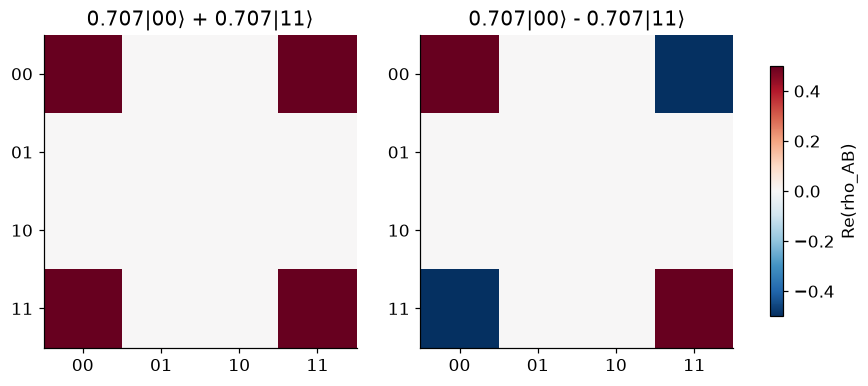

In [3]:
plus = viewer.trace_pair('00', 0.0, SEED, 1)['stages'][5]
minus = viewer.trace_pair('10', 0.0, SEED, 1)['stages'][5]
assert plus['probabilities'] == minus['probabilities']
assert plus['state_vector_notation'] != minus['state_vector_notation']
fig, axes = plt.subplots(1,2,figsize=(8,3.4),constrained_layout=True)
for ax, record in zip(axes,[plus,minus]):
    rho = np.array([[complex(*entry) for entry in row] for row in record['density_matrix']])
    image = ax.imshow(rho.real, vmin=-.5, vmax=.5, cmap='RdBu_r')
    ax.set(title=record['state_vector_notation'],xticks=range(4),yticks=range(4),
           xticklabels=viewer.LABELS,yticklabels=viewer.LABELS)
fig.colorbar(image,ax=axes,label='Re(rho_AB)',shrink=.8)
save(fig,'relative_phase')
display(fig); plt.close(fig)


## 3. Noise: ensemble eksak dibanding shot yang benar-benar disampling

Untuk depolarisasi A dengan p=0.2, peluang ideal decoding simbol benar
adalah 0.8 dan tiga simbol lain masing-masing 0.2/3. `trace_pair` memakai
Cirq density-matrix untuk ensemble dan qsimcirq untuk shot. Setiap run
mempersiapkan pasangan baru; seed dan jumlah shot dinyatakan eksplisit.


,symbol,ensemble_probability,actual_shots,sample_fraction
0,00,0.066667,23,0.044922
1,01,0.066667,41,0.080078
2,10,0.066667,47,0.091797
3,11,0.800000,401,0.783203


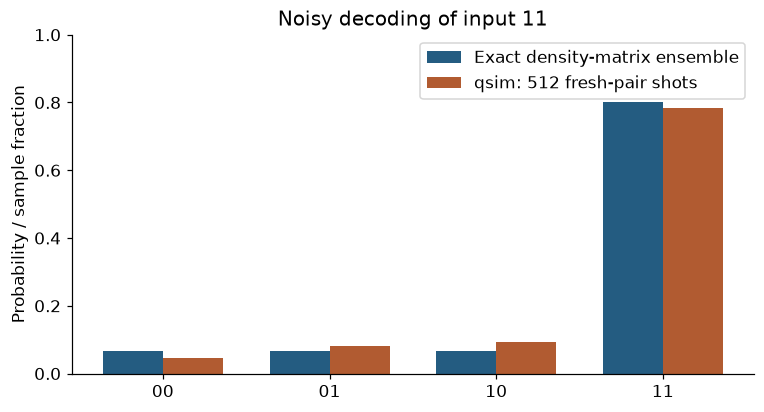

In [4]:
p = 0.2
shots = 512
noisy = viewer.trace_pair('11', p, SEED, shots)
ensemble = noisy['stages'][-2]
assert ensemble['state_vector_notation'] is None
expected = np.array([p/3,p/3,p/3,1-p])
np.testing.assert_allclose(ensemble['probabilities'], expected, atol=1e-12)
observed = np.array([noisy['histogram'][bits] for bits in viewer.LABELS])/shots
display(pd.DataFrame({'symbol':viewer.LABELS, 'ensemble_probability':expected,
                      'actual_shots':[noisy['histogram'][b] for b in viewer.LABELS], 'sample_fraction':observed}))
x = np.arange(4)
fig, ax = plt.subplots(figsize=(8,4))
ax.bar(x-.18, expected, .36, label='Exact density-matrix ensemble', color=COLORS[0])
ax.bar(x+.18, observed, .36, label=f'qsim: {shots} fresh-pair shots', color=COLORS[1])
ax.set(xticks=x,xticklabels=viewer.LABELS,ylabel='Probability / sample fraction',ylim=(0,1),title='Noisy decoding of input 11')
ax.legend()
save(fig,'noise_ensemble_vs_shots')
display(fig); plt.close(fig)


## 4. Purity global dan lokal

Kemurnian $\operatorname{Tr}(\rho^2)$ bernilai satu untuk state murni.
Marginal satu qubit pada Bell state memiliki purity 1/2 meskipun state global
murni. Dalam ensemble noisy, global purity umumnya kurang dari satu. Purity
lokal tidak otomatis merupakan ukuran entanglement untuk state global campuran.


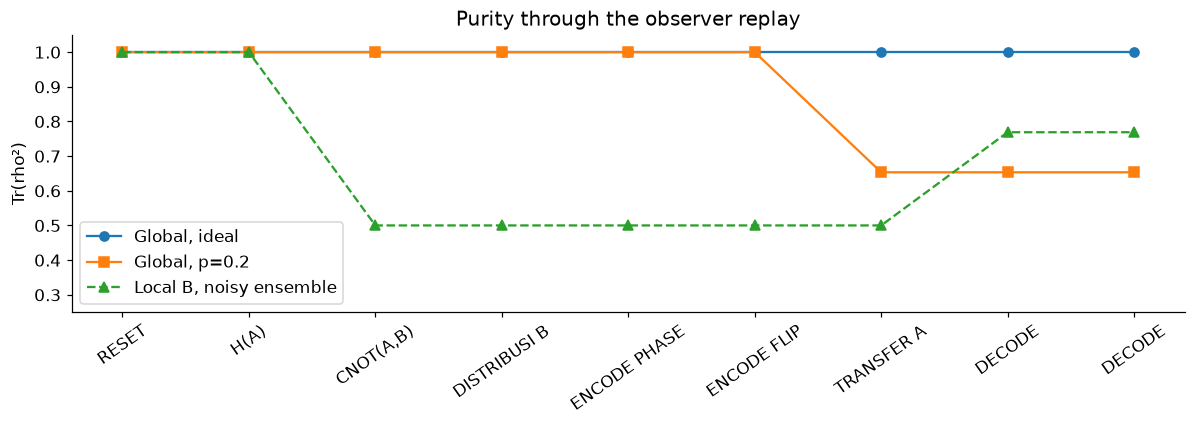

In [5]:
ideal_records = trace['stages'][:-1]
noisy_records = noisy['stages'][:-1]
fig, ax = plt.subplots(figsize=(11,4))
positions = range(len(ideal_records))
ax.plot(positions,[s['global_purity'] for s in ideal_records],'o-',label='Global, ideal')
ax.plot(positions,[s['global_purity'] for s in noisy_records],'s-',label=f'Global, p={p}')
ax.plot(positions,[s['B']['purity'] for s in noisy_records],'^--',label='Local B, noisy ensemble')
ax.set(xticks=list(positions),xticklabels=[s['title'].split(':')[0] for s in ideal_records],
       ylim=(0.25,1.05),ylabel='Tr(rho²)',title='Purity through the observer replay')
ax.tick_params(axis='x',labelrotation=35)
ax.legend()
fig.tight_layout()
save(fig,'purity_through_protocol')
display(fig); plt.close(fig)


## 5. Sesudah pengukuran: state bersyarat satu hasil

Baris akhir viewer menggambarkan state setelah outcome shot pertama
diketahui. Itu bukan ensemble sebelum measurement. Menampilkan satu hasil
sebagai peluang 100% pada tahap tersebut tidak berarti noise hilang atau
seluruh pengulangan menghasilkan simbol yang sama.


In [6]:
first = noisy['first_measurement']
collapsed = noisy['stages'][-1]['probabilities']
assert collapsed[int(first,2)] == 1.0
assert sum(noisy['histogram'].values()) == shots
print('First observed outcome:', first)
print('Conditional post-measurement probabilities:', dict(zip(viewer.LABELS,collapsed)))
print('Across independent preparations:', noisy['histogram'])


First observed outcome: 11
Conditional post-measurement probabilities: {'00': 0.0, '01': 0.0, '10': 0.0, '11': 1.0}
Across independent preparations: {'00': 23, '01': 41, '10': 47, '11': 401}


## Memakai viewer terminal

```sh
python viewer.py --bits 11 --step
python viewer.py --message 'Hai!' --pairs 1 --step
python viewer.py --bits 11 --noise 0.2 --shots 512 --json results/trace.json
```

Frame verification dan trace pasangan di mode pesan adalah run terpisah.
State global observer tidak pernah ditransmisikan ke decoder chat. Hasil
notebook ini menjelaskan model simulator, bukan akses quantum state global
yang dapat dilakukan peserta fisik dari lokasi terpisah.


## Referensi primer dan cara mengutip

1. C. H. Bennett & S. J. Wiesner (1992), *Communication via one- and two-particle
   operators on Einstein-Podolsky-Rosen states*, Physical Review Letters 69, 2881.
   [DOI: 10.1103/PhysRevLett.69.2881](https://doi.org/10.1103/PhysRevLett.69.2881).
2. [IBM Quantum Learning — superdense coding](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/entanglement-in-action/superdense-coding).
3. [IBM Quantum Learning — reduced states](https://quantum.cloud.ibm.com/learning/en/courses/general-formulation-of-quantum-information/density-matrices/multiple-systems).
4. [Google Quantum AI — qsimcirq](https://quantumai.google/qsim/tutorials/qsimcirq),
   [DepolarizingChannel](https://quantumai.google/reference/python/cirq/DepolarizingChannel).

BibTeX ada pada [docs/references.bib](../docs/references.bib), metadata software
pada [CITATION.cff](../CITATION.cff). Tidak ada DOI software atau klaim peer-review.
Notebook ini merupakan penjelasan dan verifikasi numerik protokol yang sudah ada.
